# Book-Crossing Recommender System

**Data Mining Lab — Assignment 2**

**Name:** Koushik Yadav

**Roll No:** LCS2023028

---

This notebook builds a collaborative-filtering recommender system on the Book-Crossing dataset.
The pipeline is split into three storage layers:

- `raw_layer/` — original CSV data ingested as Parquet
- `clean_layer/` — filtered and normalised tables
- `model_layer/` — sparse rating matrix and lookup artifacts used for inference

Recommendations are produced using **item-item cosine similarity** on a mean-centred user-book rating matrix.


## 0. Environment Setup


In [51]:
import csv
import io
import subprocess
import sys
from importlib.util import find_spec
from pathlib import Path
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.sparse import csr_matrix, load_npz, save_npz
from sklearn.metrics.pairwise import cosine_similarity

# Auto-install missing packages
for _pkg in ["pyarrow", "seaborn"]:
    if find_spec(_pkg) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", _pkg])

import seaborn as sns

# Global plot style
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 110

print("Environment ready.")

Environment ready.


## 1. Data Ingestion — Raw Layer

We read the three CSVs directly from the zip archive using `latin-1` encoding (required by this dataset)
and persist them as Parquet files in `raw_layer/`.  
An `ingested_at` timestamp is appended so every downstream stage can trace lineage.


In [52]:
# Storage layer paths
RAW   = Path("raw_layer")
CLEAN = Path("clean_layer")
MODEL = Path("model_layer")

for layer in (RAW, CLEAN, MODEL):
    layer.mkdir(exist_ok=True)

ARCHIVE = Path("book-crossings.zip")
assert ARCHIVE.exists(), f"Dataset not found at {ARCHIVE}. Place book-crossings.zip in this folder."

In [53]:
# CSV filename mapping inside the zip
FILE_MAP = {
    "users":   "BX-Users.csv",
    "books":   "BX-Books.csv",
    "ratings": "BX-Book-Ratings.csv",
}

ingested_at = pd.Timestamp.now(tz="UTC").floor("us")

with ZipFile(ARCHIVE) as zf:
    for name, filename in FILE_MAP.items():
        with io.TextIOWrapper(zf.open(filename), encoding="latin-1", newline="") as src:
            reader = csv.reader(src, delimiter=";", escapechar="\\", strict=True)
            df = pd.DataFrame(reader, columns=next(reader), dtype="string")
        df["ingested_at"] = ingested_at
        df.to_parquet(RAW / f"{name}.parquet", index=False)
        print(f"Saved {name}: {len(df):,} rows")

Saved users: 278,858 rows
Saved books: 271,379 rows
Saved ratings: 1,149,780 rows


## 2. Exploratory Data Analysis — Raw Layer

Before cleaning anything, we look at what the raw data actually contains:
column types, missing values, and key distributions.


### 2.1 Schema and Missing-Value Summary


In [54]:
raw = {name: pd.read_parquet(RAW / f"{name}.parquet") for name in FILE_MAP}

def schema_report(df, label):
    """Print row count and a dtype/missing-value table for a DataFrame."""
    print(f"\n{'='*50}")
    print(f"  {label}:  {df.shape[0]:,} rows  x  {df.shape[1]} columns")
    print(f"{'='*50}")
    missing = (df.isna() | df.isin(["", "NULL"])).sum()
    report = pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": missing,
                            "missing%": (missing / len(df) * 100).round(2)})
    display(report)

schema_report(raw["users"],   "Users")
schema_report(raw["books"],   "Books")
schema_report(raw["ratings"], "Ratings")


  Users:  278,858 rows  x  4 columns


,dtype,missing,missing%
User-ID,string,0,0.0000
Location,string,0,0.0000
Age,string,110762,39.7200
ingested_at,"datetime64[us, UTC]",0,0.0000



  Books:  271,379 rows  x  9 columns


,dtype,missing,missing%
ISBN,string,0,0.0000
Book-Title,string,0,0.0000
Book-Author,string,0,0.0000
Year-Of-Publication,string,0,0.0000
Publisher,string,0,0.0000
Image-URL-S,string,0,0.0000
Image-URL-M,string,0,0.0000
Image-URL-L,string,0,0.0000
ingested_at,"datetime64[us, UTC]",0,0.0000



  Ratings:  1,149,780 rows  x  4 columns


,dtype,missing,missing%
User-ID,string,0,0.0000
ISBN,string,0,0.0000
Book-Rating,string,0,0.0000
ingested_at,"datetime64[us, UTC]",0,0.0000


### 2.2 Rating Score Distribution

Ratings range from 0 to 10. A score of **0 is implicit** (the user interacted with the book but did not rate it numerically), while scores 1–10 are **explicit**. The chart below shows this split clearly.


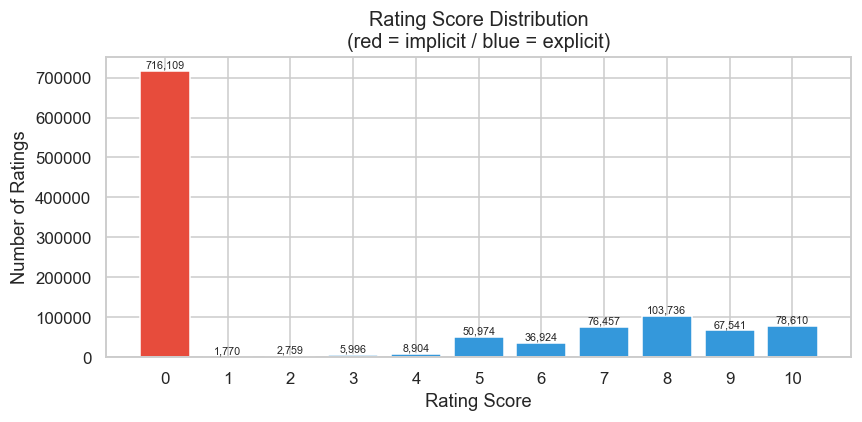

Implicit (0) ratings : 716,109  (62.3%)
Explicit (1-10) ratings: 433,671  (37.7%)


In [55]:
score_col = pd.to_numeric(raw["ratings"]["Book-Rating"])
score_counts = score_col.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 4))
colors = ["#e74c3c" if s == 0 else "#3498db" for s in score_counts.index]
bars = ax.bar(score_counts.index, score_counts.values, color=colors, edgecolor="white")
ax.set_xlabel("Rating Score", fontsize=12)
ax.set_ylabel("Number of Ratings", fontsize=12)
ax.set_title("Rating Score Distribution\n(red = implicit / blue = explicit)", fontsize=13)
ax.set_xticks(range(11))
for bar in bars:
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 2000,
            f"{bar.get_height():,}", ha="center", va="bottom", fontsize=7)
plt.tight_layout()
plt.show()

print(f"Implicit (0) ratings : {score_counts[0]:,}  ({score_counts[0]/len(score_col):.1%})")
print(f"Explicit (1-10) ratings: {score_counts[1:].sum():,}  ({score_counts[1:].sum()/len(score_col):.1%})")

### 2.3 User Age and Book Publication Year Distribution


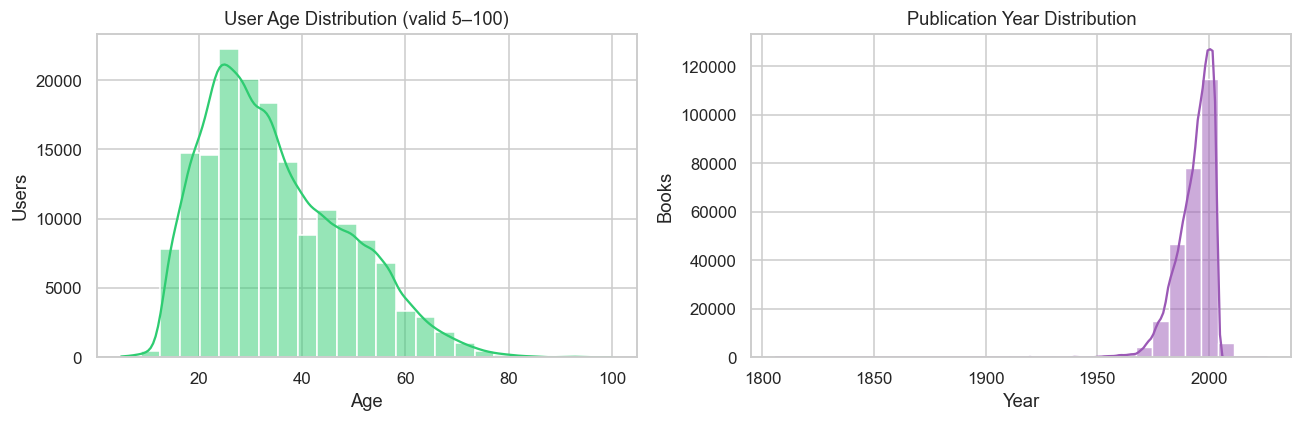

Ages out of range (< 5 or > 100): 1,248
Publication year = 0 (unknown)   : 4,619
Future publication year          : 11


In [56]:
age_col  = pd.to_numeric(raw["users"]["Age"],               errors="coerce")
year_col = pd.to_numeric(raw["books"]["Year-Of-Publication"], errors="coerce")
current_year = pd.Timestamp.now(tz="UTC").year

valid_ages  = age_col[age_col.between(5, 100)]
valid_years = year_col[year_col.between(1800, current_year)]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(valid_ages,  bins=25, ax=axes[0], color="#2ecc71", kde=True)
axes[0].set(title="User Age Distribution (valid 5–100)",
            xlabel="Age", ylabel="Users")

sns.histplot(valid_years, bins=30, ax=axes[1], color="#9b59b6", kde=True)
axes[1].set(title="Publication Year Distribution",
            xlabel="Year", ylabel="Books")

plt.tight_layout()
plt.show()

print(f"Ages out of range (< 5 or > 100): {(age_col.notna() & ~age_col.between(5, 100)).sum():,}")
print(f"Publication year = 0 (unknown)   : {year_col.eq(0).sum():,}")
print(f"Future publication year          : {year_col.gt(current_year).sum():,}")

### 2.4 Top 10 Most-Reviewed Books

This chart highlights which books attract the most user attention regardless of score.


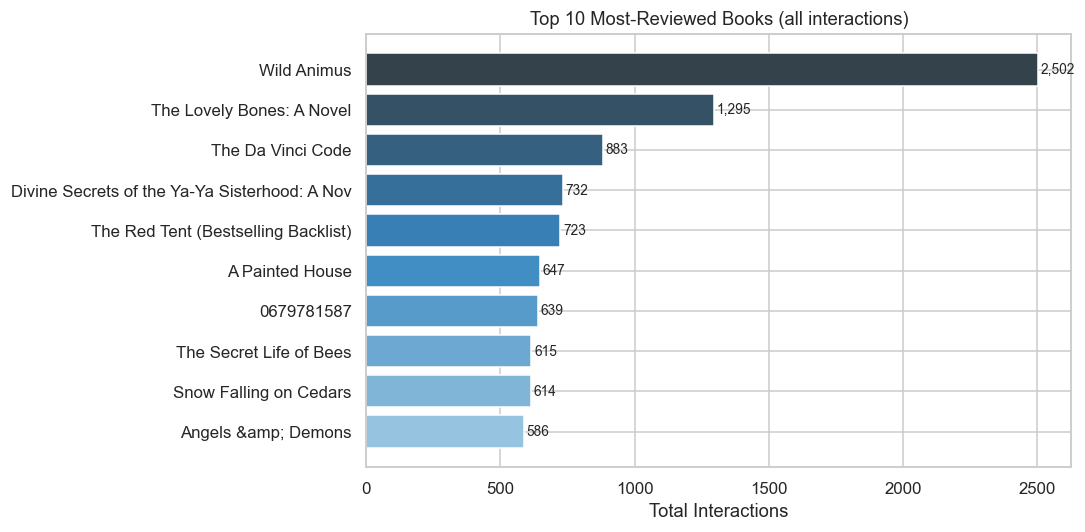

In [57]:
# Count all interactions (implicit + explicit) per ISBN
isbn_counts = raw["ratings"]["ISBN"].value_counts().head(10)

# Map ISBN -> Book Title
isbn_to_title = raw["books"].set_index("ISBN")["Book-Title"].to_dict()
top_labels = [isbn_to_title.get(isbn, isbn)[:45] for isbn in isbn_counts.index]

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(top_labels[::-1], isbn_counts.values[::-1],
               color=sns.color_palette("Blues_d", 10))
ax.set_xlabel("Total Interactions")
ax.set_title("Top 10 Most-Reviewed Books (all interactions)")
for bar in bars:
    ax.text(bar.get_width() + 10, bar.get_y() + bar.get_height() / 2,
            f"{int(bar.get_width()):,}", va="center", fontsize=9)
plt.tight_layout()
plt.show()

### 2.5 Top 10 Most Prolific Authors


C:\Users\koush\AppData\Local\Temp\ipykernel_12216\506121260.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=author_counts.values, y=author_counts.index, palette="rocket", ax=ax)


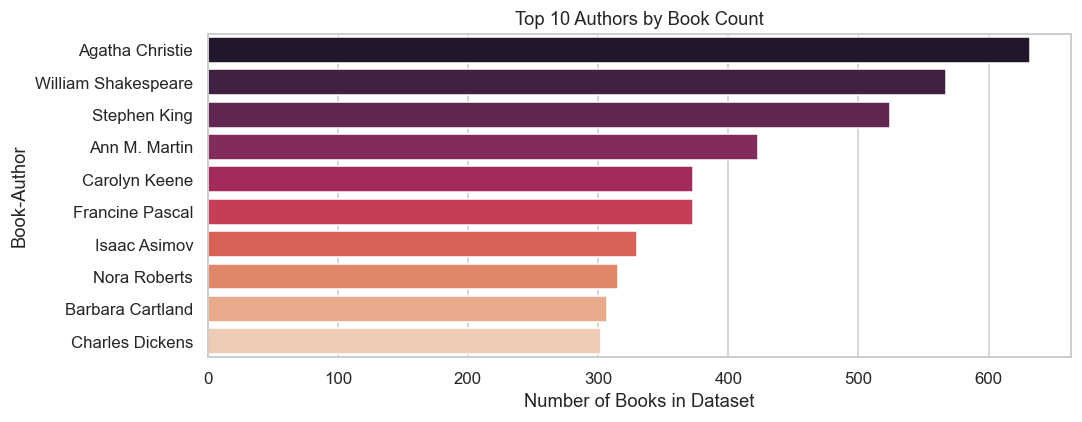

In [58]:
author_counts = raw["books"]["Book-Author"].value_counts().head(10)

fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(x=author_counts.values, y=author_counts.index, palette="rocket", ax=ax)
ax.set_xlabel("Number of Books in Dataset")
ax.set_title("Top 10 Authors by Book Count")
plt.tight_layout()
plt.show()

### 2.6 Interaction Sparsity Analysis

Collaborative filtering performance is directly affected by how sparse the rating matrix is.
The more sparse, the harder it is to find similar users/items.


In [59]:
MIN_INTERACTIONS = 12   # minimum explicit ratings for a user/book to be included

pairs = raw["ratings"][["User-ID", "ISBN"]]
valid_users = raw["users"]["User-ID"]
valid_isbns = raw["books"]["ISBN"]
linked = pairs["User-ID"].isin(valid_users) & pairs["ISBN"].isin(valid_isbns)

explicit_mask = score_col.between(1, 10)
explicit_pairs = pairs.loc[linked & explicit_mask].drop_duplicates()

total_cells = len(valid_users) * len(valid_isbns)

for col in ("User-ID", "ISBN"):
    cnts = pairs[col].value_counts()
    exp_cnts = explicit_pairs[col].value_counts()
    pct_below = (cnts < MIN_INTERACTIONS).mean()
    n_active  = (exp_cnts >= MIN_INTERACTIONS).sum()
    print(f"{col}: median interactions = {cnts.median():g}, "
          f"{pct_below:.1%} have fewer than {MIN_INTERACTIONS}")
    print(f"  → {n_active:,} with at least {MIN_INTERACTIONS} explicit ratings\n")

filled_pct = len(explicit_pairs) / total_cells * 100
print(f"Explicit rating density: {filled_pct:.6f}% ({100 - filled_pct:.6f}% empty)")

User-ID: median interactions = 1, 89.4% have fewer than 12
  → 5,504 with at least 12 explicit ratings

ISBN: median interactions = 1, 95.8% have fewer than 12
  → 4,263 with at least 12 explicit ratings

Explicit rating density: 0.000507% (99.999493% empty)


## 3. Data Cleaning — Clean Layer

We now produce clean, strongly-typed tables from the raw Parquet files.
Invalid ages are replaced by the median; invalid publication years are set to `NA`.
Only explicit ratings (1–10) with matching users and books are retained.


### 3.1 Helper Utilities


In [60]:
def select_rename(source_df, col_map):
    """Select and rename columns from a raw DataFrame, dropping duplicates."""
    return source_df[list(col_map)].drop_duplicates().rename(columns=col_map)

def normalise_text(series):
    """Collapse whitespace and strip leading/trailing spaces."""
    return series.str.replace(r"\s+", " ", regex=True).str.strip()

### 3.2 Clean Users — Age and Location


In [61]:
user_df = select_rename(raw["users"], {"User-ID": "user_id", "Age": "age", "Location": "location"})
user_df["user_id"] = user_df["user_id"].astype(int)

# Age: coerce to numeric, clamp to plausible range, fill outliers with median
age_num = pd.to_numeric(user_df["age"], errors="coerce")
age_num = age_num.where(age_num.between(5, 100))
user_df["age"] = age_num.fillna(age_num.median())

# Location: split into city / state / country
loc_parts = user_df.pop("location").str.rsplit(",", n=2)
user_df["city"]    = loc_parts.str[0]
user_df["state"]   = loc_parts.str[1].where(loc_parts.str.len().eq(3))
user_df["country"] = loc_parts.str[-1].where(loc_parts.str.len().ge(2))

BAD_VALS = ["", "n/a", '"n/a"']
for col in ("city", "state", "country"):
    user_df[col] = normalise_text(user_df[col]).str.casefold().replace(BAD_VALS, pd.NA)

print(f"Users after cleaning: {len(user_df):,}")
user_df.head(3)

Users after cleaning: 278,858


,user_id,age,city,state,country
0,1,32,nyc,new york,usa
1,2,18,stockton,california,usa
2,3,32,moscow,yukon territory,russia


### 3.3 Clean Books


In [62]:
book_df = select_rename(raw["books"], {
    "ISBN": "book_id",
    "Book-Title": "title",
    "Book-Author": "author",
    "Year-Of-Publication": "pub_year",
    "Publisher": "publisher",
})

for col in ("title", "author", "publisher"):
    book_df[col] = normalise_text(book_df[col])
book_df["publisher"] = book_df["publisher"].str.casefold()

# Case-folded title key for deduplication
book_df["title_key"] = book_df["title"].str.casefold()

# Publication year: drop zeros and future years
pub_yr = pd.to_numeric(book_df["pub_year"], errors="coerce")
book_df["pub_year"] = pub_yr.where(pub_yr.between(1, current_year)).astype("Int64")

print(f"Books after cleaning: {len(book_df):,}")
book_df.head(3)

Books after cleaning: 271,379


,book_id,title,author,pub_year,publisher,title_key
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,oxford university press,classical mythology
1,0002005018,Clara Callan,Richard Bruce Wright,2001,harperflamingo canada,clara callan
2,0060973129,Decision in Normandy,Carlo D'Este,1991,harperperennial,decision in normandy


### 3.4 Filter Explicit Ratings


In [63]:
ratings_df = select_rename(raw["ratings"],
                            {"User-ID": "user_id", "ISBN": "book_id", "Book-Rating": "rating"})
ratings_df = ratings_df.astype({"user_id": int, "rating": int})

# Keep only ratings where both user and book exist in our clean tables
known_user = ratings_df["user_id"].isin(user_df["user_id"])
known_book = ratings_df["book_id"].isin(book_df["book_id"])
ratings_df = ratings_df[known_user & known_book]

# Keep only explicit ratings (1–10); average if same user rated same book more than once
ratings_df = ratings_df[ratings_df["rating"].between(1, 10)]
ratings_df = ratings_df.groupby(["user_id", "book_id"], as_index=False)["rating"].mean()

print(f"Explicit ratings: {len(ratings_df):,}")

Explicit ratings: 383,852


### 3.5 Apply Minimum Interaction Filter

We iteratively drop users and books with fewer than `MIN_INTERACTIONS = 12` explicit ratings
until the constraint holds for the entire remaining set.  
This threshold is higher than a simple cut-off and reduces data sparsity more aggressively.


In [64]:
iteration = 0
while True:
    u_cnt = ratings_df.groupby("user_id")["rating"].transform("size")
    b_cnt = ratings_df.groupby("book_id")["rating"].transform("size")
    keep  = u_cnt.ge(MIN_INTERACTIONS) & b_cnt.ge(MIN_INTERACTIONS)
    if keep.all():
        break
    ratings_df = ratings_df[keep].copy()
    iteration += 1

print(f"Converged in {iteration} iteration(s).")
print(f"Retained ratings : {len(ratings_df):,}")
print(f"Retained users   : {ratings_df['user_id'].nunique():,}")
print(f"Retained books   : {ratings_df['book_id'].nunique():,}")

Converged in 16 iteration(s).
Retained ratings : 21,660
Retained users   : 918
Retained books   : 977


### 3.6 Build Reading History and Save Clean Tables


In [65]:
# Restrict users and books to those surviving the filter
active_users = ratings_df["user_id"].unique()
active_books = ratings_df["book_id"].unique()

user_df = user_df[user_df["user_id"].isin(active_users)].sort_values("user_id").reset_index(drop=True)
book_df = book_df[book_df["book_id"].isin(active_books)].sort_values("book_id").reset_index(drop=True)

# Reading history: all interactions (implicit + explicit) for active users
all_interactions = select_rename(raw["ratings"],
                                  {"User-ID": "user_id", "ISBN": "book_id"})
all_interactions = all_interactions.astype({"user_id": int})
history_df = (
    all_interactions[all_interactions["user_id"].isin(active_users)]
    .merge(book_df[["book_id", "title_key"]], on="book_id")
    [["user_id", "title_key"]]
    .drop_duplicates()
)

# Book-level aggregate stats
book_stats = ratings_df.groupby("book_id").agg(
    rating_count=("rating", "size"),
    rating_mean=("rating", "mean")
).reset_index()

# Persist
frames = {
    "users":       user_df,
    "books":       book_df,
    "ratings":     ratings_df,
    "history":     history_df,
    "book_stats":  book_stats,
}
for fname, frame in frames.items():
    frame.to_parquet(CLEAN / f"{fname}.parquet", index=False)
    print(f"{fname:12s}: {len(frame):,} rows saved")

users       : 918 rows saved
books       : 977 rows saved
ratings     : 21,660 rows saved
history     : 52,773 rows saved
book_stats  : 977 rows saved


## 4. Feature Engineering — Model Layer

We build a **sparse user × book matrix** where each cell holds the explicit rating.
Before computing similarities we **mean-centre each user's ratings** (subtract that user's average rating).
This corrects for user bias — a strict rater giving 6/10 means something different from a lenient rater giving 6/10.


In [66]:
# Assign integer row/column indices
user_index = pd.Series(range(len(user_df)), index=user_df["user_id"])   # user_id  -> row
book_index = pd.Series(range(len(book_df)), index=book_df["book_id"])   # book_id  -> col

rows = ratings_df["user_id"].map(user_index).values
cols = ratings_df["book_id"].map(book_index).values

# Raw rating matrix (users x books)
rating_matrix = csr_matrix(
    (ratings_df["rating"].values.astype(np.float32), (rows, cols)),
    shape=(len(user_df), len(book_df)),
)

# Mean-centre per user (subtract each user's mean rating from their entries)
user_means = np.array(rating_matrix.sum(axis=1)).flatten() / np.diff(rating_matrix.indptr)
centred_data = rating_matrix.data.copy()
for i in range(rating_matrix.shape[0]):
    start, end = rating_matrix.indptr[i], rating_matrix.indptr[i + 1]
    centred_data[start:end] -= user_means[i]

centred_matrix = csr_matrix(
    (centred_data, rating_matrix.indices.copy(), rating_matrix.indptr.copy()),
    shape=rating_matrix.shape,
)

print(f"Rating matrix shape : {rating_matrix.shape}")
print(f"Non-zero entries    : {rating_matrix.nnz:,}")
print(f"Density             : {rating_matrix.nnz / (rating_matrix.shape[0] * rating_matrix.shape[1]):.4%}")

Rating matrix shape : (918, 977)
Non-zero entries    : 21,660
Density             : 2.4150%


In [67]:
# Save model artifacts
save_npz(MODEL / "rating_matrix.npz",   rating_matrix)
save_npz(MODEL / "centred_matrix.npz",  centred_matrix)

user_df[["user_id"]].to_parquet(MODEL / "user_index.parquet",  index=False)
book_df[["book_id", "title", "author", "pub_year", "title_key"]].to_parquet(
    MODEL / "book_lookup.parquet", index=False)
history_df.to_parquet(  MODEL / "history.parquet",    index=False)
book_stats.to_parquet(  MODEL / "book_stats.parquet", index=False)

print("Model layer saved.")

Model layer saved.


## 5. Recommendation Engine

We implement two recommendation modes:

| Function                 | What it does                                                                   |
| ------------------------ | ------------------------------------------------------------------------------ |
| `books_like(title)`      | Finds books whose rating patterns are most similar to a given book             |
| `recommend_for(user_id)` | Recommends books based on the user's highly-rated books (weighted cosine)      |
| `popular_books()`        | Fallback: returns the most-rated books (useful when user data is insufficient) |


### 5.1 Load Model Artifacts


In [68]:
rating_mat  = load_npz(MODEL / "rating_matrix.npz")
centred_mat = load_npz(MODEL / "centred_matrix.npz")
book_mat    = centred_mat.T.tocsr()     # books x users (for item-item similarity)

u_ids   = pd.read_parquet(MODEL / "user_index.parquet")["user_id"]
u_row   = pd.Series(u_ids.index, index=u_ids)   # user_id -> matrix row

lookup  = pd.read_parquet(MODEL / "book_lookup.parquet")
hist    = pd.read_parquet(MODEL / "history.parquet").set_index("user_id")["title_key"]
stats   = pd.read_parquet(MODEL / "book_stats.parquet").set_index("book_id")

lookup["rating_count"] = lookup["book_id"].map(stats["rating_count"])
lookup["rating_mean"]  = lookup["book_id"].map(stats["rating_mean"]).round(2)

LIKE_THRESHOLD = 7    # ratings >= this are treated as "liked"

print(f"Loaded {len(lookup):,} books and {len(u_ids):,} users.")

Loaded 977 books and 918 users.


### 5.2 Scoring and Ranking Helper


In [69]:
def rank_results(scores_arr, skip_titles, n=10):
    """
    Given a similarity score per book row, return the top-n results
    excluding books whose title_key is in skip_titles.
    Ties are broken by rating_count (more reviews = ranked higher).
    """
    result = lookup.assign(similarity=scores_arr)
    result = result[result["similarity"] > 0]
    result = result[~result["title_key"].isin(skip_titles)]
    result = result.sort_values(
        ["similarity", "rating_count", "book_id"],
        ascending=[False, False, True]
    ).drop_duplicates("title_key")
    return (
        result[["title", "author", "rating_count", "similarity"]]
        .head(max(n, 0))
        .rename(columns={"similarity": "score"})
        .reset_index(drop=True)
    )

### 5.3 Item-Item: Books Similar to a Given Title


In [70]:
def books_like(title, n=10):
    """
    Return the n books most similar to `title`.
    If multiple editions share the same title, we pick the one with the most ratings.
    """
    key = " ".join(title.split()).casefold()
    matches = lookup[lookup["title_key"] == key]
    if matches.empty:
        raise ValueError(f"Title not found in dataset: '{title}'")
    seed_row = matches["rating_count"].idxmax()
    sim_scores = cosine_similarity(book_mat, book_mat[[seed_row]])[:, 0]
    return rank_results(sim_scores, [key], n)

### 5.4 User-Based: Personalised Recommendations


In [71]:
def recommend_for(user_id, n=10):
    """
    Recommend n books for a given user.
    Uses weighted average of cosine similarities to books the user rated >= LIKE_THRESHOLD.
    Falls back to popular_books() if the user has no liked books.
    """
    if user_id not in u_row:
        raise ValueError(f"User {user_id} not found in the filtered dataset.")

    user_vec  = rating_mat.getrow(u_row.loc[user_id])
    liked_idx = user_vec.indices[user_vec.data >= LIKE_THRESHOLD]
    liked_wts = user_vec.data[user_vec.data >= LIKE_THRESHOLD]

    if len(liked_idx) == 0:
        print(f"User {user_id} has no ratings >= {LIKE_THRESHOLD}. Returning popular books.")
        return popular_books(n)

    sim_matrix = cosine_similarity(book_mat, book_mat[liked_idx])  # (n_books, n_liked)
    agg_scores = np.average(sim_matrix, axis=1, weights=liked_wts)

    already_seen = hist.loc[[user_id]] if user_id in hist.index else pd.Series([], dtype=str)
    return rank_results(agg_scores, already_seen, n)


def popular_books(n=10):
    """Return the n globally most-rated books as a simple popularity-based fallback."""
    result = lookup.sort_values(["rating_count", "rating_mean"], ascending=False)
    result = result.drop_duplicates("title_key")
    return result[["title", "author", "rating_count", "rating_mean"]].head(n).reset_index(drop=True)

## 6. Results

### 6.1 Sanity Checks


In [72]:
pd.set_option("display.max_colwidth", None)
pd.set_option("display.float_format", "{:.4f}".format)

# Every user and book must have at least MIN_INTERACTIONS ratings
assert rating_mat.getnnz(axis=1).min() >= MIN_INTERACTIONS, "User constraint violated!"
assert rating_mat.getnnz(axis=0).min() >= MIN_INTERACTIONS, "Book constraint violated!"

print(f"min ratings per user : {rating_mat.getnnz(axis=1).min()}")
print(f"min ratings per book : {rating_mat.getnnz(axis=0).min()}")
print("All constraints satisfied ✓")

min ratings per user : 12
min ratings per book : 12
All constraints satisfied ✓


### 6.2 Item-Item Example


In [73]:
# Pick the top rated book automatically from your dataset:
sample_book = lookup.sort_values("rating_count", ascending=False).iloc[0]["title"]
print(f"=== Books similar to '{sample_book}' ===")
display(books_like(sample_book))

=== Books similar to 'The Lovely Bones: A Novel' ===


,title,author,rating_count,score
0,Flesh and Blood,Jonathan Kellerman,13,0.2594
1,Rainbow Six,Tom Clancy,16,0.2386
2,Tough Cookie,Diane Mott Davidson,12,0.2220
3,The Green Mile: The Complete Serial Novel,Stephen King,13,0.1505
4,Open House (Oprah's Book Club (Paperback)),Elizabeth Berg,17,0.1343
5,The Body Farm,Patricia Daniels Cornwell,33,0.1282
6,Invisible Monsters,Chuck Palahniuk,15,0.1267
7,Seven Up (A Stephanie Plum Novel),Janet Evanovich,13,0.1242
8,Empty Promises,Ann Rule,12,0.1186
9,The River King,Alice Hoffman,13,0.1173


### 6.3 Personalised Recommendations for Three Users

For each user we show:

1. The books they rated most highly (≥ 7)
2. The 10 personalised recommendations


In [74]:
def show_user_report(uid):
    print(f"\n{'━'*60}")
    print(f"  USER  {uid}")
    print(f"{'━'*60}")

    # Liked books (rated >= LIKE_THRESHOLD)
    user_vec = rating_mat.getrow(u_row.loc[uid])
    liked_idx = user_vec.indices[user_vec.data >= LIKE_THRESHOLD]
    liked_wts = user_vec.data[user_vec.data >= LIKE_THRESHOLD]
    liked_titles = lookup.iloc[liked_idx][["title", "author"]].copy()
    liked_titles.insert(2, "user_rating", liked_wts)
    liked_titles = liked_titles.sort_values("user_rating", ascending=False).reset_index(drop=True)

    print(f"\nHighly-rated books (score >= {LIKE_THRESHOLD}):")
    display(liked_titles)

    print("\nRecommendations:")
    display(recommend_for(uid))


# Pick three users that survived filtering
sample_users = u_ids.iloc[[10, 50, 120]].tolist()
for uid in sample_users:
    show_user_report(uid)


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  USER  5476
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

Highly-rated books (score >= 7):


,title,author,user_rating
0,Keeping Faith : A Novel,Jodi Picoult,10.0000
1,The Da Vinci Code,Dan Brown,10.0000
2,Rules of Prey,John Sandford,8.0000
3,Saint Maybe,ANNE TYLER,8.0000
4,The Final Judgment,Richard North Patterson,7.0000
5,The Nanny Diaries: A Novel,Emma McLaughlin,7.0000



Recommendations:


,title,author,rating_count,score
0,The Devil Wears Prada : A Novel,LAUREN WEISBERGER,23,0.0938
1,Four Blind Mice,James Patterson,18,0.0769
2,Hornet's Nest,Patricia Daniels Cornwell,19,0.0708
3,Mystic River,Dennis Lehane,26,0.0660
4,Stalker: A Peter Decker and Rina Lazarus Novel,Faye Kellerman,13,0.0643
5,The Perfect Husband,LISA GARDNER,17,0.0630
6,Don't Sweat the Small Stuff and It's All Small Stuff : Simple Ways to Keep the Little Things from Taking Over Your Life (Don't Sweat the Small Stuff Series),Richard Carlson,20,0.0593
7,Fear Nothing,DEAN KOONTZ,22,0.0589
8,When the Wind Blows,James Patterson,36,0.0588
9,Winter Prey,John Sandford,12,0.0529



━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  USER  17003
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

Highly-rated books (score >= 7):


,title,author,user_rating
0,Stupid White Men ...and Other Sorry Excuses for the State of the Nation!,Michael Moore,10.0000
1,The Bean Trees,Barbara Kingsolver,10.0000
2,Animal Dreams,Barbara Kingsolver,10.0000
3,Fast Food Nation: The Dark Side of the All-American Meal,Eric Schlosser,10.0000
4,The Hours: A Novel,Michael Cunningham,10.0000
5,Bastard Out of Carolina,Dorothy Allison,10.0000
6,"Dude, Where's My Country?",Michael Moore,10.0000
7,Shopgirl : A Novella,Steve Martin,10.0000
8,The Lovely Bones: A Novel,Alice Sebold,9.0000
9,East of Eden (Oprah's Book Club),John Steinbeck,9.0000


... (2 outputs left out)


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  USER  39345
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

Highly-rated books (score >= 7):


,title,author,user_rating
0,Cruel &amp; Unusual (Kay Scarpetta Mysteries (Paperback)),Patricia D. Cornwell,10.0000
1,The Rainmaker,JOHN GRISHAM,10.0000
2,The Runaway Jury,JOHN GRISHAM,10.0000
3,The Firm,John Grisham,10.0000
4,The Da Vinci Code,Dan Brown,9.0000
5,Unnatural Exposure,Patricia Daniels Cornwell,9.0000
6,The Door to December,Dean R. Koontz,9.0000
7,Bleachers,John Grisham,8.0000
8,The Chamber,John Grisham,8.0000
9,Beach Music,Pat Conroy,8.0000



Recommendations:


,title,author,rating_count,score
0,The Pelican Brief,John Grisham,66,0.0546
1,Dr. Death (Alex Delaware Novels (Paperback)),Jonathan Kellerman,15,0.0541
2,The Cat in the Hat,Dr. Seuss,14,0.0501
3,Chicken Soup for the Woman's Soul (Chicken Soup for the Soul Series (Paper)),Jack Canfield,25,0.0498
4,Silent Prey,John Sandford,13,0.0494
5,The Street Lawyer,JOHN GRISHAM,42,0.0474
6,Chosen Prey,John Sandford,23,0.0459
7,White Oleander : A Novel,Janet Fitch,13,0.0449
8,All That Remains (Kay Scarpetta Mysteries (Paperback)),Patricia D. Cornwell,28,0.0445
9,Deception Point,Dan Brown,18,0.0445


### 6.4 Popularity Fallback Demo


In [75]:
print("=== Top 10 Most-Rated Books (Popularity Fallback) ===")
display(popular_books(10))

=== Top 10 Most-Rated Books (Popularity Fallback) ===


,title,author,rating_count,rating_mean
0,The Lovely Bones: A Novel,Alice Sebold,162,8.2700
1,The Da Vinci Code,Dan Brown,121,8.6800
2,The Red Tent (Bestselling Backlist),Anita Diamant,101,8.5200
3,The Secret Life of Bees,Sue Monk Kidd,87,8.7700
4,Divine Secrets of the Ya-Ya Sisterhood: A Novel,Rebecca Wells,84,8.0800
5,Where the Heart Is (Oprah's Book Club (Paperback)),Billie Letts,82,8.2400
6,Harry Potter and the Order of the Phoenix (Book 5),J. K. Rowling,80,9.0700
7,Good in Bed,Jennifer Weiner,79,8.0600
8,Harry Potter and the Sorcerer's Stone (Harry Potter (Paperback)),J. K. Rowling,78,9.0400
9,The Firm,John Grisham,78,8.0100


## 7. Summary

| Step                        | Description                                                                         |
| --------------------------- | ----------------------------------------------------------------------------------- |
| **Raw Layer**               | Loaded Users, Books, Ratings from zip into Parquet with timestamps                  |
| **EDA**                     | Analysed score distribution, age/year histograms, top books, top authors, sparsity  |
| **Clean Layer**             | Clamped ages, split locations, normalised book text, retained explicit ratings only |
| **Min-interactions filter** | `MIN_INTERACTIONS = 12` applied iteratively — both users and books                  |
| **Model Layer**             | Sparse user×book matrix built; mean-centred per user to correct for rating bias     |
| **Recommender**             | Item-item cosine similarity on centred matrix; weighted average over liked books    |
| **Fallback**                | `popular_books()` for users with no highly-rated books                              |

**Key hyperparameters:**

- `MIN_INTERACTIONS = 12`
- `LIKE_THRESHOLD = 7`
